<a href="https://colab.research.google.com/github/Atika-Adelia/Repo-Kelompok07-ProyekStudio02/blob/main/Studio2_Kelompok07_RB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Studio 2 — Kompetisi Klasifikasi Sampah (5 kelas)**

**Deep Learning (IF25-40401) RB | Teknik Informatika | Institut Teknologi Sumatera**

**Dosen Pengampu : Rahman Indra Kesuma, S.Kom., M.Cs. dan Meida Cahyo Untoro, S.Kom., M.Kom.**

---

**Nama Anggota Kelompok 07:**

1. Hildyah Maretasya Araffad (123140151)
2. Firman H Gultom (123140171)
3. Atika Adelia (123140172)



## **1. Setup, Konfigurasi, dan Reproduktibilitas**


### **1.1 Library yang digunakan**

In [ ]:
# Library yang digunakan pada percobaan proyek studio 02
import os, sys, json, math, copy, time, random, shutil
import hashlib, platform, subprocess, importlib.util, urllib.request, gc
from dataclasses import dataclass, asdict
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

# Untuk data numerik, tabel, dan visualisasi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

IN_COLAB = 'google.colab' in sys.modules

# timm dan pytorch
try:
    import timm
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'timm'])
    import timm

import torch
import torch.nn as nn

# Untuk loading Data
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# Untuk transformasi dan augmentasi gambar
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode
from timm.data import Mixup

# Fungsi loss pada timm
from timm.loss import SoftTargetCrossEntropy

# Fungsi evaluasi metrik
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

# Untuk pembagian data
from sklearn.model_selection import train_test_split

# Untuk tampilan progress bar
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw):
        return x

# Kelas
CLASSES = ['botol_plastik', 'gelas_plastik', 'kertas_kardus',
           'saset_kemasan', 'styrofoam']
NUM_CLASSES = len(CLASSES)
# Jenis format file
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}

### **1.2 Konfigurasi**

In [ ]:
@dataclass
class CFG:
    # Path
    data_root: str = '/content/drive/MyDrive/dataset_studio2'
    repo_dir: str = '/content/studio2' if IN_COLAB else '.'
    sources_csv: str = ''
    copy_to_local: bool = True
    local_data_dir: str = 'data_local'
    backup_dir: str = '/content/drive/MyDrive/studio2_backup'
    extra_dirs: tuple = ()
    cache_dir: str = 'cache'
    runs_dir: str = 'runs'
    cache_max_side: int = 512

    # Model
    backbone: str = 'convnext_tiny.fb_in22k_ft_in1k'
    img_size: int = 224
    drop_path: float = 0.1
    drop_rate: float = 0.2

    # Optimasi
    epochs: int = 15
    warmup_epochs: int = 1
    batch_size: int = 32
    lr_backbone: float = 1e-4
    lr_head: float = 1e-3
    weight_decay: float = 0.05
    label_smoothing: float = 0.1
    mixup: float = 0.2
    cutmix: float = 1.0
    mix_prob: float = 0.5
    mix_off_last: int = 3
    ema_decay: float = 0.995
    grad_clip: float = 1.0
    sampler: str = 'none'

    # Evaluasi
    val_frac: float = 0.15
    select: str = 'last'

    # Sistem
    seed: int = 42
    num_workers: int = (
        0 if platform.system() == 'Windows'
        else min(4, os.cpu_count() or 2)
    )
    amp: bool = True


cfg = CFG()
assert cfg.batch_size % 2 == 0, 'batch_size harus genap'

### **1.3 Set Folder**

In [ ]:
REPO = Path(cfg.repo_dir)
REPO.mkdir(parents=True, exist_ok=True)
REPO = REPO.resolve()
os.chdir(REPO)

# Folder Cadangan
def drive_backup_dir():
    if IN_COLAB and Path('/content/drive/MyDrive').is_dir():
        return Path(cfg.backup_dir)
    return None

def backup_to_drive(paths=('runs', 'submission', 'README.md', '.gitignore')):
    bd = drive_backup_dir()
    if bd is None:
        return
    n = 0
    for p in paths:
        src = Path(p)
        if not src.exists():
            continue
        files = [src] if src.is_file() else [f for f in src.rglob('*') if f.is_file()]
        for f in files:
            dst = bd / f
            if dst.exists() and dst.stat().st_size == f.stat().st_size:
                continue
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(f, dst)
            n += 1
    if n:
        print(f'[backup] {n} file disalin ke {bd}')

def restore_from_drive():
    bd = drive_backup_dir()
    if bd is None or not (bd / 'runs').exists():
        return
    n = 0
    for sub in ('runs', 'submission'):
        for f in (bd / sub).rglob('*') if (bd / sub).exists() else []:
            if f.is_file() and not (REPO / sub / f.relative_to(bd / sub)).exists():
                dst = REPO / sub / f.relative_to(bd / sub)
                dst.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(f, dst)
                n += 1
    if n:
        print(f'[restore] {n} file dipulihkan dari {bd}')


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(cfg.seed)

### **1.4 Set Runtime Type**

In [ ]:
# Runtime type
if torch.cuda.is_available():
    DEVICE = 'cuda'
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'
USE_AMP = cfg.amp and DEVICE == 'cuda'
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.get_device_capability()[0] >= 8) else torch.float16
torch.backends.cudnn.benchmark = True

In [ ]:
print(f'Repo         : {REPO}')
print(f'torch/timm   : {torch.__version__} / {timm.__version__}')
print(f'Device       : {DEVICE}' + (f' ({torch.cuda.get_device_name(0)})' if DEVICE == 'cuda' else ''))
print(f'AMP          : {USE_AMP} ({AMP_DTYPE if USE_AMP else "-"})')
print(f'Backbone     : {cfg.backbone} @ {cfg.img_size}px | {cfg.epochs} epoch | batch {cfg.batch_size}')

Repo         : /content/studio2
torch/timm   : 2.11.0+cu130 / 1.0.30
Device       : cuda (Tesla T4)
AMP          : True (torch.float16)
Backbone     : convnext_tiny.fb_in22k_ft_in1k @ 224px | 15 epoch | batch 32


## **2. Dataset: Lokasi, Integritas, dan Eksplorasi**

**Sumber data:** `cfg.data_root = /content/drive/MyDrive/dataset_studio2`

### **2.1 Load Dataset**

In [ ]:
# Menghubungkan ke google drive
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    # Memulihkan runs/ dan submission/ dari
    # cadangan Drive bila ada
    restore_from_drive()

Mounted at /content/drive
[restore] 8 file dipulihkan dari /content/drive/MyDrive/studio2_backup


In [ ]:
# Cek Folder Dataset di Gdrive
def is_train_root(p):
    p = Path(p)
    return p.is_dir() and all((p / k).is_dir() for k in CLASSES)


def find_train_root(candidates):
    for c in candidates:
        if c and is_train_root(c):
            return Path(c)
    for base in ('/content/drive/MyDrive', '/content', '/kaggle/input', '.'):
        b = Path(base)
        if not b.is_dir():
            continue
        for pat in ('*/botol_plastik', '*/*/botol_plastik', '*/*/*/botol_plastik'):
            for hit in b.glob(pat):
                if is_train_root(hit.parent):
                    return hit.parent
    return None


DATA_ORIG = find_train_root([cfg.data_root, '/content/drive/MyDrive/dataset_studio2',
                             './train', '../train', '/content/train'])
if DATA_ORIG is None:
    hint = ''
    if Path('/content/drive/MyDrive').is_dir():
        hint = 'Isi My Drive: ' + ', '.join(sorted(
            p.name for p in Path('/content/drive/MyDrive').iterdir())[:25])
    raise FileNotFoundError('Folder dataset tidak ditemukan' + hint)
print('Lokasi dataset di Gdrive =', DATA_ORIG)

Lokasi dataset di Gdrive = /content/drive/MyDrive/dataset_studio2


In [ ]:
# Salin dataset dari GDrive ke disk lokal Colab
# Agar proses running lebih cepat

def mirror_to_local(src_root, dst_root):
    src_root, dst_root = Path(src_root), Path(dst_root)
    jobs = []
    for cls in CLASSES:
        for p in sorted((src_root / cls).iterdir()):
            if p.suffix.lower() in IMG_EXTS:
                jobs.append((p, dst_root / cls / p.name))

    def cp(job):
        src, dst = job
        if not dst.exists() or dst.stat().st_size != src.stat().st_size:
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(src, dst)

    with ThreadPoolExecutor(max_workers=16) as ex:
        list(tqdm(ex.map(cp, jobs), total=len(jobs),
                  desc='salin dataset dari Drive'))
    return dst_root


TRAIN_ROOT = DATA_ORIG
if cfg.copy_to_local and str(DATA_ORIG).startswith('/content/drive'):
    TRAIN_ROOT = mirror_to_local(DATA_ORIG, Path(cfg.local_data_dir) / 'train')
print('Lokasi train pada Gcolab =', TRAIN_ROOT)

salin dataset dari Drive:   0%|          | 0/2753 [00:00<?, ?it/s]

Lokasi train pada Gcolab = data_local/train


In [ ]:
# Hitung jumlah gambar per kelas (data raw)
rows = []
for cls in CLASSES:
    entries = list((DATA_ORIG / cls).iterdir())
    n_img = sum(p.suffix.lower() in IMG_EXTS for p in entries)
    rows.append((cls, n_img, len(entries) - n_img))

print(f'\n{"Kelas":<20}{"Gambar":>8}{"Bukan Gambar":>12}')
for cls, n_img, n_other in rows:
    print(f'{cls:<20}{n_img:>8}{n_other:>12}')
print(f'{"Total Gambar":<20}{sum(r[1] for r in rows):>8}{sum(r[2] for r in rows):>12}')


Kelas                 GambarBukan Gambar
botol_plastik            523           0
gelas_plastik            521           0
kertas_kardus            365           0
saset_kemasan            673           0
styrofoam                671           0
Total Gambar            2753           0


### **2.2 Cek Kualitas Dataset**

In [ ]:
# Mengecek integritas gambar

def list_items(root):
    items = []
    # Mengubah indeks kelas menjadi label integer
    for ci, cls in enumerate(CLASSES):
        d = Path(root) / cls
        if d.is_dir():
            items += [(str(p), ci) for p in sorted(d.iterdir()) if p.suffix.lower() in IMG_EXTS]
    return items

# Fungsi untuk menghitung hash isi file
def md5_of(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

# Meriksa setiap gambar
def inspect_one(item):
    p, y = item
    try:
        with Image.open(p) as im:
            im.load()
            w, h, mode = im.width, im.height, im.mode
        return dict(path=p, label=y, w=w, h=h, mode=mode,
                    kb=os.path.getsize(p) / 1024, md5=md5_of(p),
                    ok=True, err='')
    except Exception as e:
        return dict(path=p, label=y, w=0, h=0, mode='', kb=0.0,
                    md5='', ok=False, err=str(e)[:80])

# Proses meriksa setiap gambar
FOUND = list_items(TRAIN_ROOT)
with ThreadPoolExecutor(max_workers=8) as ex:
    scan = pd.DataFrame(list(tqdm(ex.map(inspect_one, FOUND),
                                  total=len(FOUND), desc='memeriksa gambar')))

memeriksa gambar:   0%|          | 0/2753 [00:00<?, ?it/s]

### **2.3 Cleaning dataset**

In [ ]:
# Cleaning data gambar

# Clean gambar rusak atau tidak terbaca
bad = scan[~scan.ok]
good = scan[scan.ok].copy()

# Clean gambar duplikat
good['is_dup'] = good.duplicated('md5', keep=False)

# Menampung hash yang muncul dengan lebih dari satu label
n_lbl = good.groupby('md5')['label'].nunique()
conflict_md5 = set(n_lbl[n_lbl > 1].index)
# Membuang semua salinan gambar yang labelnya konflik
clean = good[~good.md5.isin(conflict_md5)].drop_duplicates('md5')

RAW_ITEMS = list(zip(clean.path, clean.label.astype(int)))

In [ ]:
print(f'Jumlah Gambar Setelah Audit.   : {len(scan)}')
print(f'Gambar Rusak                   : {len(bad)}')
print(f'Gambar Duplikasi               : {int(good.is_dup.sum())} file di {good[good.is_dup].md5.nunique()} grup')
print(f'Jumlah grup berlabel konflik   : {len(conflict_md5)} (semua salinannya dibuang)')
print(f'Jumlah Gambar setelah cleaning : {len(RAW_ITEMS)}')

Jumlah Gambar Setelah Audit.   : 2753
Gambar Rusak                   : 0
Gambar Duplikasi               : 0 file di 0 grup
Jumlah grup berlabel konflik   : 0 (semua salinannya dibuang)
Jumlah Gambar setelah cleaning : 2753


In [ ]:
# Menghitung jumlah gambar per kelas
if len(bad):
    display(bad[['path', 'err']].head(10))

tabel = clean.groupby('label').size().rename('jumlah').to_frame()
tabel.index = [CLASSES[i] for i in tabel.index]
tabel['persen'] = (tabel.jumlah / tabel.jumlah.sum() * 100).round(1)
display(tabel)

print('Rasio kelas terbesar/terkecil: %.2f' % (tabel.jumlah.max() / tabel.jumlah.min()))

,jumlah,persen
botol_plastik,523,19.0
gelas_plastik,521,18.9
kertas_kardus,365,13.3
saset_kemasan,673,24.4
styrofoam,671,24.4


Rasio kelas terbesar/terkecil: 1.84


### **2.2 Cek Ukuran dan Warna Gambar**

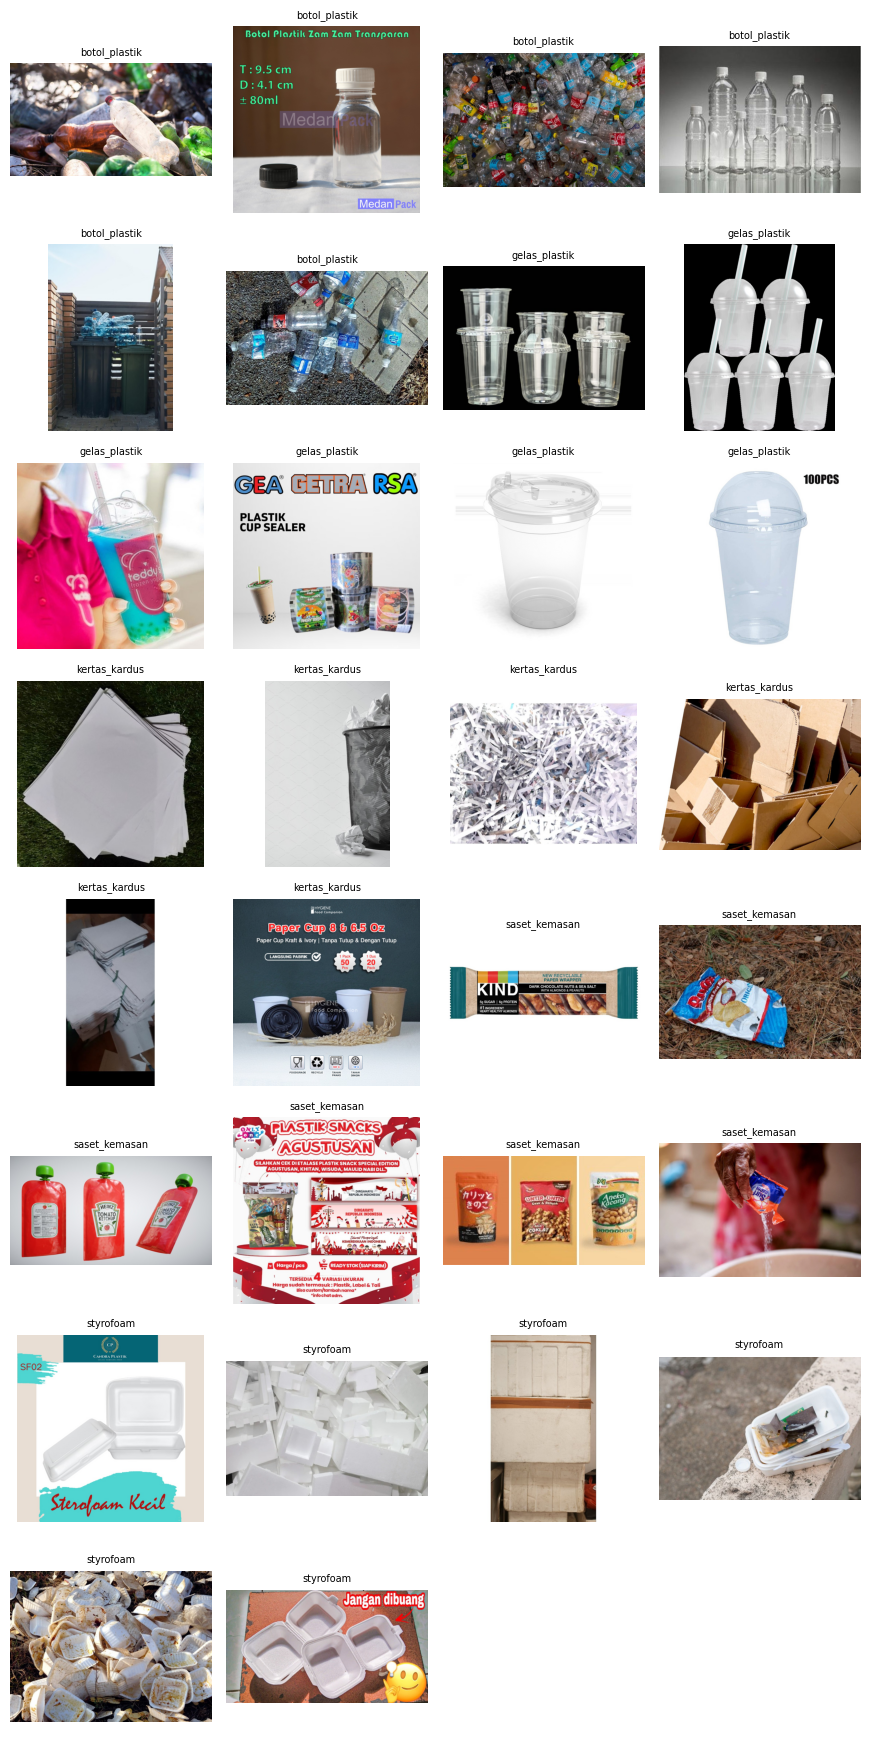

In [ ]:
# Menampilkan gambar dari seluruh kelas
def show_grid(paths, titles=None, ncols=4, size=2.2):
    n = len(paths)
    nrows = math.ceil(n / ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    axs = np.array(axs).reshape(-1)
    for ax in axs:
        ax.axis('off')
    for i, p in enumerate(paths):
        with Image.open(p) as im:
            axs[i].imshow(im.convert('RGB'))
        if titles is not None:
            axs[i].set_title(titles[i], fontsize=7)
    plt.tight_layout()
    plt.show()

rng = random.Random(cfg.seed)
pick = []
for ci in range(NUM_CLASSES):
    pool = [p for p, y in RAW_ITEMS if y == ci]
    pick += rng.sample(pool, min(6, len(pool)))
show_grid(pick, [CLASSES[[y for p, y in RAW_ITEMS if p == q][0]] for q in pick])

In [ ]:
# Menampilkan ukuran gambar dan warna pada dataset
print('Ukuran gambar asli (piksel):')
display(clean[['w', 'h', 'kb']].describe().round(0).loc[['min', '50%', 'max']])
print('Mode warna :', clean['mode'].value_counts().to_dict())

Ukuran gambar asli (piksel):


,w,h,kb
min,150.0,150.0,3.0
50%,800.0,753.0,101.0
max,1024.0,1024.0,501.0


Mode warna : {'RGB': 2753}


## **3. Split Validasi Lokal, `my_val/`, dan Cache Gambar**


### **3.1 Split train val**

In [ ]:
# Split train/val berbasis indeks
y_all = np.array([l for _, l in RAW_ITEMS])
tr_idx, va_idx = train_test_split(np.arange(len(RAW_ITEMS)),
                                  test_size=cfg.val_frac,
                                  stratify=y_all,
                                  random_state=cfg.seed)
tr_idx, va_idx = np.sort(tr_idx), np.sort(va_idx)

### **3.2 Inisialisasi Fungsi Cache Gambar**

In [ ]:
# Inisialisasi fungsi cache gambar
# Tempat menyimpan gambar setelah pre-processing

# Fungsi untuk memproses satu gambar
def cache_one(args):
    src, y, cache_dir, max_side = args
    tag = hashlib.md5(src.encode()).hexdigest()[:8]
    dst = Path(cache_dir) / CLASSES[y] / f'{Path(src).stem}_{tag}.jpg'
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(src) as im:
            # tanpa exif_transpose
            im = im.convert('RGB')
            if max(im.size) > max_side:
                s = max_side / max(im.size)
                im = im.resize((max(1, round(im.width * s)),
                                max(1, round(im.height * s))),
                               Image.Resampling.LANCZOS)
            im.save(dst, quality=95)
    return (str(dst), y)

# Fungsi untuk memproses seluruh gambar
def build_cache(items, cache_dir, max_side):
    jobs = [(p, y, cache_dir, max_side) for p, y in items]
    with ThreadPoolExecutor(max_workers=8) as ex:
        return list(tqdm(ex.map(cache_one, jobs), total=len(jobs),
                         desc='cache gambar'))

ALL_RAW = RAW_ITEMS
ALL_ITEMS = build_cache (ALL_RAW,
                         cfg.cache_dir,
                         cfg.cache_max_side) if cfg.cache_max_side > 0 else list(ALL_RAW)

# Path Cache Gambar
ORIG_OF = {c: o for (c, _), (o, _) in zip(ALL_ITEMS, ALL_RAW)}
MAIN_ITEMS = ALL_ITEMS[:len(RAW_ITEMS)], ALL_ITEMS[len(RAW_ITEMS):]

cache gambar:   0%|          | 0/2753 [00:00<?, ?it/s]

### **3.3 Audit Label Gambar**

In [ ]:
# Audit label, mengecek apabila terdapat label yang salah pada gambar
# Terisi setelah audit label
# Berisi gambar yang memiliki label yang salah
EXCLUDE_NAMES = set()

def apply_exclude(items):
    return [it for it in items if Path(ORIG_OF[it[0]]).name not in EXCLUDE_NAMES]

### **3.4 Hasil Split Data**

In [ ]:
# Susunan hasil spil data
SPLIT = dict(train=[ALL_ITEMS[i] for i in tr_idx],
             val=[ALL_ITEMS[i] for i in va_idx])

# Menyalin gambar validasi asli ke folder per kelas
def write_my_val(raw_items, idx, dst='my_val'):
    dst = Path(dst)
    if dst.exists():
        shutil.rmtree(dst)
    for i in idx:
        p, y = raw_items[i]
        out = dst / CLASSES[y]
        out.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, out / Path(p).name)


write_my_val(RAW_ITEMS, va_idx)
Path(cfg.runs_dir).mkdir(exist_ok=True)
Path(cfg.runs_dir, 'split.json').write_text(json.dumps(dict(
    seed=cfg.seed, val_frac=cfg.val_frac,
    val_files=[Path(RAW_ITEMS[i][0]).name for i in va_idx]), indent=1))

cnt = lambda its: np.bincount([y for _, y in its],
                              minlength=NUM_CLASSES).tolist()

In [ ]:
# Rangkuman hasil spil data dan chace gambar
print(f'Jumlah data train : {len(SPLIT["train"])}')
print(f'Jumlah data val :  {len(SPLIT["val"])}')
print('Jumlah gambar per kelas (train) :', cnt(SPLIT['train']))
print('Jumlah gambar per kelas (val) :', {c: len(list(Path('my_val', c).glob('*'))) for c in CLASSES})

Jumlah data train : 2340
Jumlah data val :  413
Jumlah gambar per kelas (train) : [445, 443, 310, 572, 570]
Jumlah gambar per kelas (val) : {'botol_plastik': 78, 'gelas_plastik': 78, 'kertas_kardus': 55, 'saset_kemasan': 101, 'styrofoam': 101}


## **4. Dataset dan Transformasi**

### **4.1 Transformasi Training dan Evaluasi**

In [ ]:
BICUBIC = InterpolationMode.BICUBIC

# Training
def build_train_tf(size, mean, std):
    return T.Compose([
        T.RandomResizedCrop(size, scale=(0.35, 1.0),
                            ratio=(3 / 4, 4 / 3),
                            interpolation=BICUBIC),
        T.RandomHorizontalFlip(),
        T.TrivialAugmentWide(interpolation=InterpolationMode.BILINEAR),
        T.ToTensor(),
        T.Normalize(mean, std),
        T.RandomErasing(p=0.2, value='random'),
    ])

# Evaluasi
def build_eval_tf(size, mean, std):
    return T.Compose([
        T.Resize((size, size), interpolation=BICUBIC),
        T.ToTensor(),
        T.Normalize(mean, std),
    ])

### **4.2 Dataset dan Data Loader**

In [ ]:
# Kelas Gambar
class ImageDS(Dataset):
    def __init__(self, items, tf):
        self.items, self.tf = items, tf

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        p, y = self.items[i]
        with Image.open(p) as im:
            img = im.convert('RGB')
        return self.tf(img), y


def _worker_init(_):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s)
    random.seed(s)


def make_loader(items, tf, bs, train, cfg, gen=None, sampler=None):
    nw = cfg.num_workers
    return DataLoader(ImageDS(items, tf), batch_size=bs,
                      shuffle=(train and sampler is None),
                      sampler=sampler,drop_last=train, num_workers=nw,
                      pin_memory=(DEVICE == 'cuda'),
                      persistent_workers=(nw > 0),generator=gen,
                      worker_init_fn=_worker_init if nw > 0 else None)

## **5. Model, EMA, dan Training Loop**

### **5.1 Arsitektur Model dan Normalisasi**

In [ ]:
# Arsitektur Model
def create_model(cfg, pretrained=True, backbone=None):
    name = backbone or cfg.backbone
    try:
        return timm.create_model(name, pretrained=pretrained,
                                 num_classes=NUM_CLASSES,
                                 drop_rate=cfg.drop_rate,
                                 drop_path_rate=cfg.drop_path)
    except TypeError:
        return timm.create_model(name, pretrained=pretrained,
                                 num_classes=NUM_CLASSES)

# Normalisasi
def norm_of(model):
    pc = getattr(model, 'pretrained_cfg', None) or {}
    mean = tuple(float(x) for x in pc.get('mean', (0.485, 0.456, 0.406)))
    std = tuple(float(x) for x in pc.get('std', (0.229, 0.224, 0.225)))
    return mean, std

### **5.2 EMA (Exponential Moving Average)**

In [ ]:
# Kelas Salinan Bobot
class EMA:
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.updates = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        src = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(src[k].detach(), alpha=1 - d)
            else:
                v.copy_(src[k])

### **5.3 Pengaturan Parameter Optimizer**

In [ ]:
# Fungsi Parameter untuk optimizer
def make_param_groups(model, cfg):
    head_ids = {id(p) for p in model.get_classifier().parameters()}
    buckets = {('bb', True): [], ('bb', False): [], ('hd', True): [], ('hd', False): []}
    for n, p in model.named_parameters():
        if p.requires_grad:
            buckets[('hd' if id(p) in head_ids else 'bb',
                     p.ndim > 1 and not n.endswith('.bias'))].append(p)
    groups = []
    for (part, decay), ps in buckets.items():
        if ps:
            groups.append(dict(params=ps, lr=cfg.lr_head if part == 'hd' else cfg.lr_backbone,
                               weight_decay=cfg.weight_decay if decay else 0.0))
    return groups

### **5.4 Mixed Precision dan Pemindahan Tensor**

In [ ]:
def amp_ctx():
    return torch.autocast(device_type='cuda', dtype=AMP_DTYPE, enabled=USE_AMP)


def to_dev(x):
    x = x.to(DEVICE, non_blocking=True)
    return x.contiguous(memory_format=torch.channels_last) if DEVICE == 'cuda' else x

### **5.5 Evaluasi, Macro F1-Score, dan Penyimpanan Bobot**

In [ ]:
@torch.no_grad()

# Evaluasi
def run_eval(model, loader, tta=False):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        x = to_dev(x)
        with amp_ctx():
            p = model(x).float().softmax(-1)
            if tta:
                p = (p + model(torch.flip(x, dims=[-1])).float().softmax(-1)) / 2
        probs.append(p.cpu())
        labels.append(y)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()

# Untuk Macro F1-Score
def macro_f1(y, p):
    return float(f1_score(y, p.argmax(1), average='macro',
                          labels=list(range(NUM_CLASSES)),
                          zero_division=0))

def cpu_state(m):
    return {k: v.detach().cpu().contiguous().clone() for k, v in m.state_dict().items()}

RUNS_PATH = Path(cfg.runs_dir) / 'runs.json'
RUNS = json.loads(RUNS_PATH.read_text()) if RUNS_PATH.exists() else {}

# Menyimpan informasi training
def register_run(tag, info):
    RUNS[tag] = info
    RUNS_PATH.write_text(json.dumps(RUNS, indent=1))

# Memuat Model
def load_run_model(tag):
    info = RUNS[tag]
    m = timm.create_model(info['arch'], pretrained=False,
                          num_classes=NUM_CLASSES)
    m.load_state_dict(torch.load(info['state_path'], map_location='cpu',
                                 weights_only=True), strict=True)
    return m.to(DEVICE).eval()

### **5.6 Training Model**

In [ ]:
# Untuk menjalankan training model
def train_model(cfg, train_items, val_items=None, tag='run'):
    assert cfg.batch_size % 2 == 0, 'batch size harus genap'
    seed_everything(cfg.seed)
    arch = cfg.backbone.split('.')[0]
    # Model
    model = create_model(cfg, pretrained=True).to(DEVICE)
    if DEVICE == 'cuda':
        model = model.to(memory_format=torch.channels_last)
    # Mean/std normalisasi
    mean, std = norm_of(model)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6

    # Data
    # Generator acak pada DataLoader
    gen = torch.Generator()
    gen.manual_seed(cfg.seed)
    sampler = None
    if cfg.sampler == 'sqrt':
        cnt_c = np.bincount([y for _, y in train_items],
                            minlength=NUM_CLASSES).astype(float)
        w = [1.0 / math.sqrt(cnt_c[y]) for _, y in train_items]
        sampler = WeightedRandomSampler(w, num_samples=len(train_items),
                                        replacement=True, generator=gen)
    train_dl = make_loader(train_items, build_train_tf(cfg.img_size, mean, std),
                           cfg.batch_size, True, cfg, gen, sampler)
    val_dl = make_loader(val_items, build_eval_tf(cfg.img_size, mean, std),
                         64, False, cfg) if val_items else None

    #  Optimizer & learning-rate schedule
    steps_per_epoch = len(train_items) // cfg.batch_size
    total_steps, warm_steps = cfg.epochs * steps_per_epoch, cfg.warmup_epochs * steps_per_epoch
    opt = torch.optim.AdamW(make_param_groups(model, cfg))

    def lr_mult(step):
        if step < warm_steps:
            return (step + 1) / max(1, warm_steps)
        prog = (step - warm_steps) / max(1, total_steps - warm_steps)
        return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * prog))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_mult)
    use_scaler = USE_AMP and AMP_DTYPE == torch.float16
    try:
        scaler = torch.amp.GradScaler('cuda', enabled=use_scaler)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=use_scaler)

    # Augmentasi Mixup/CutMix & loss
    use_mix = (cfg.mixup > 0 or cfg.cutmix > 0) and cfg.mix_prob > 0
    mixup_fn = Mixup(mixup_alpha=cfg.mixup, cutmix_alpha=cfg.cutmix,
                     prob=cfg.mix_prob, switch_prob=0.5, mode='batch',
                     label_smoothing=cfg.label_smoothing, num_classes=NUM_CLASSES) if use_mix else None
    crit = SoftTargetCrossEntropy() if use_mix else nn.CrossEntropyLoss(label_smoothing=cfg.label_smoothing)
    ema = EMA(model, cfg.ema_decay)

    print(f'[{tag}] {arch} | {n_params:.1f} jt param | train {len(train_items)} | val {len(val_items) if val_items else 0} | '
          f'{steps_per_epoch} iter/epoch')
    hist, best, t_start = [], dict(f1=-1.0), time.time()
    p_last = None
    # Loop epoch
    for ep in range(1, cfg.epochs + 1):
        model.train()
        if mixup_fn is not None and ep > cfg.epochs - cfg.mix_off_last:
            mixup_fn.mixup_enabled = False
        t0, run_loss, nb = time.time(), 0.0, 0
        for x, y in train_dl:
            x, y = to_dev(x), y.to(DEVICE, non_blocking=True)
            tgt = y
            if mixup_fn is not None:
                x, tgt = mixup_fn(x, y)
            with amp_ctx():
                out = model(x)
            loss = crit(out.float(), tgt)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if cfg.grad_clip:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(),
                                               cfg.grad_clip)
            scaler.step(opt)
            scaler.update()
            sched.step()
            ema.update(model)
            run_loss += loss.item()
            nb += 1
        row = dict(epoch=ep, train_loss=run_loss / max(1, nb), sec=time.time() - t0)
        msg = f'  ep {ep:02d}/{cfg.epochs} | loss {row["train_loss"]:.3f}'
        if val_dl is not None:
            p_ema, yv = run_eval(ema.module, val_dl)
            p_raw, _ = run_eval(model, val_dl)
            row.update(f1_ema=macro_f1(yv, p_ema),
                       acc_ema=float(accuracy_score(yv, p_ema.argmax(1))),
                       f1_raw=macro_f1(yv, p_raw))
            msg += f' | val F1 ema {row["f1_ema"]:.4f} acc {row["acc_ema"]:.4f} | F1 raw {row["f1_raw"]:.4f}'
            p_last = p_ema
            if cfg.select == 'best' and row['f1_ema'] > best['f1']:
                best = dict(f1=row['f1_ema'], epoch=ep, state=cpu_state(ema.module),
                            probs=p_ema)
        hist.append(row)
        eta = (time.time() - t_start) / ep * (cfg.epochs - ep)
        print(msg + f' | {row["sec"]:.0f}s (sisa ±{eta / 60:.1f} mnt)')

    # Pilih bobot akhir
    if cfg.select == 'best' and val_dl is not None and 'state' in best:
        state, probs, chosen = best['state'], best['probs'], best['epoch']
    else:
        state, probs, chosen = cpu_state(ema.module), p_last, cfg.epochs
    state_path = str(Path(cfg.runs_dir) / f'{tag}.pth')
    torch.save(state, state_path)
    info = dict(tag=tag, arch=arch, backbone=cfg.backbone, img_size=cfg.img_size,
                epochs=cfg.epochs, chosen_epoch=chosen,mean=mean, std=std,
                state_path=state_path, minutes=round((time.time() - t_start) / 60, 1),
                cfg=asdict(cfg), val_f1=None, val_acc=None, history=hist,
                n_train=len(train_items), n_val=(len(val_items) if val_items else 0))
    res = dict(info=info, history=hist, val_probs=probs, val_labels=(yv if val_dl is not None else None))
    if val_dl is not None:
        info['val_f1'] = macro_f1(yv, probs)
        info['val_acc'] = float(accuracy_score(yv, probs.argmax(1)))
        np.savez(Path(cfg.runs_dir) / f'{tag}_val.npz', probs=probs, labels=yv)
        print(f'[{tag}] SELESAI | epoch terpilih {chosen} | val Macro-F1 {info["val_f1"]:.4f} | acc {info["val_acc"]:.4f} | {info["minutes"]} mnt')
    else:
        print(f'[{tag}] SELESAI (tanpa validasi) | {info["minutes"]} mnt')
    register_run(tag, info)
    backup_to_drive()

    # Membersihkan memori
    del model, ema, opt, train_dl, val_dl
    gc.collect()
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    return res

### **5.7 Perbandingan Hasil Eksperimen**

In [ ]:
# Untuk merangkum semua eksperimen
def compare_runs():
    rows = [dict(tag=t, arch=i['arch'], img=i['img_size'],
                 epochs=i['epochs'], ep_dipilih=i['chosen_epoch'],
                 val_F1=i['val_f1'], val_acc=i['val_acc'],
                 menit=i['minutes']) for t, i in RUNS.items()]
    return pd.DataFrame(rows).sort_values('val_F1', ascending=False,
                                          na_position='last') if rows else pd.DataFrame()

### **5.8 Persiapan Cache Konfigurasi**

In [ ]:
CFG_IGNORE = ('data_root', 'repo_dir', 'backup_dir', 'cache_dir', 'runs_dir',
              'num_workers', 'sources_csv', 'local_data_dir', 'copy_to_local')

# Untuk mengambil parameter konfigurasi model
def _cfg_key(d):
    return json.loads(json.dumps({k: v for k, v in d.items() if k not in CFG_IGNORE}))

### **5.9 Cache Training dan Pemanggilan Model**

In [ ]:
# Fungsi wrapper yang bertindak sebagai sistem Cache cerdas untuk menghemat waktu
def get_or_train(cfg, train_items, val_items=None, tag='run', force=False):
    # Pakai hasil tersimpan bila konfigurasi dan ukuran data identik
    info = RUNS.get(tag)
    npz = Path(cfg.runs_dir) / f'{tag}_val.npz'
    if (info is not None and not force and Path(info['state_path']).exists() and 'history' in info
            and _cfg_key(info['cfg']) == _cfg_key(asdict(cfg))
            and info.get('n_train') == len(train_items) and info.get('n_val') == (len(val_items) if val_items else 0)
            and (not val_items or npz.exists())):
        print(f'[{tag}] memakai hasil tersimpan (konfigurasi sama). Gunakan force=True untuk melatih ulang.')
        if val_items:
            z = np.load(npz)
            return dict(info=info, history=info['history'], val_probs=z['probs'],
                        val_labels=z['labels'])
        return dict(info=info, history=info['history'], val_probs=None,
                    val_labels=None)
    return train_model(cfg, train_items, val_items, tag=tag)

## **6. Run A — Hold-out**


### **6.1 Training Run**

In [ ]:
RUN_A = 'holdout_' + cfg.backbone.split('.')[0] + f'_{cfg.img_size}'
# True = abaikan hasil tersimpan dan latih ulang
FORCE_RETRAIN = True
res_a = get_or_train(cfg, apply_exclude(SPLIT['train']), SPLIT['val'],
                     tag=RUN_A, force=FORCE_RETRAIN)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

[holdout_convnext_tiny_224] convnext_tiny | 27.8 jt param | train 2340 | val 413 | 73 iter/epoch
  ep 01/15 | loss 1.207 | val F1 ema 0.9201 acc 0.9225 | F1 raw 0.9244 | 30s (sisa ±8.7 mnt)
  ep 02/15 | loss 0.840 | val F1 ema 0.9347 acc 0.9370 | F1 raw 0.9254 | 16s (sisa ±6.3 mnt)
  ep 03/15 | loss 0.765 | val F1 ema 0.9367 acc 0.9395 | F1 raw 0.9507 | 16s (sisa ±5.2 mnt)
  ep 04/15 | loss 0.721 | val F1 ema 0.9514 acc 0.9516 | F1 raw 0.9409 | 16s (sisa ±4.5 mnt)
  ep 05/15 | loss 0.683 | val F1 ema 0.9600 acc 0.9613 | F1 raw 0.9476 | 16s (sisa ±4.0 mnt)
  ep 06/15 | loss 0.668 | val F1 ema 0.9675 acc 0.9685 | F1 raw 0.9503 | 16s (sisa ±3.5 mnt)
  ep 07/15 | loss 0.675 | val F1 ema 0.9697 acc 0.9709 | F1 raw 0.9503 | 16s (sisa ±3.1 mnt)
  ep 08/15 | loss 0.566 | val F1 ema 0.9641 acc 0.9661 | F1 raw 0.9616 | 16s (sisa ±2.6 mnt)
  ep 09/15 | loss 0.592 | val F1 ema 0.9712 acc 0.9734 | F1 raw 0.9718 | 16s (sisa ±2.2 mnt)
  ep 10/15 | loss 0.585 | val F1 ema 0.9737 acc 0.9758 | F1 raw 0.

- raw (model) adalah bobot asli yang langsung diperbarui oleh AdamW
- EMA (ema.module) adalah rata-rata bergerak dari bobot raw tersebut.

### **6.2 Definisi Fungsi Evaluasi**

In [ ]:
# Visualisasi riwayat training
def plot_history(hist, title=''):
    h = pd.DataFrame(hist)
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
    axs[0].plot(h.epoch, h.train_loss, marker='o')
    axs[0].set_title('Training loss')
    axs[0].set_xlabel('epoch')
    axs[0].grid(alpha=.3)

    if 'f1_ema' in h:
        axs[1].plot(h.epoch, h.f1_ema, marker='o', label='EMA (dipakai)')
        axs[1].plot(h.epoch, h.f1_raw, marker='s',
                    label='model biasa', alpha=.7)
        axs[1].set_title('Macro-F1 validasi lokal')
        axs[1].set_xlabel('epoch')
        axs[1].legend()
        axs[1].grid(alpha=.3)

    plt.suptitle(title, color='gray')
    plt.tight_layout()
    plt.show()


# Classification report dan confusion matrix
def report(y, probs, title=''):
    pred = probs.argmax(1)
    print(
        f'=== {title} | Macro-F1 {macro_f1(y, probs):.4f} '
        f'| Akurasi {accuracy_score(y, pred):.4f}'
    )
    print(classification_report(
        y, pred, target_names=CLASSES,
        digits=4, zero_division=0
    ))

    cm = confusion_matrix(y, pred, labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASSES, rotation=40, ha='right', fontsize=8)
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_yticklabels(CLASSES, fontsize=8)

    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(
                j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black',
                fontsize=8
            )

    ax.set_xlabel('prediksi')
    ax.set_ylabel('label asli')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


# Menampilkan Contoh Prediksi yang Salah
def show_errors(items, y, probs, k=4):
    pred = probs.argmax(1)
    wrong = np.where(pred != y)[0]

    print("=== Contoh Prediksi yang Salah ===")

    if len(wrong) == 0:
        print("Tidak ada gambar yang salah diprediksi.")
        return

    wrong = wrong[
        np.argsort(-probs[wrong, pred[wrong]])
    ][:k]

    print(f"Menampilkan {len(wrong)} dari "
          f"{np.sum(pred != y)} gambar yang salah diprediksi.")

    show_grid(
        [items[i][0] for i in wrong],
        [
            f"Asli: {CLASSES[y[i]]}\n"
            f"Prediksi: {CLASSES[pred[i]]} "
            f"({probs[i, pred[i]]:.2f})"
            for i in wrong
        ],
        ncols=2,
        size=3
    )

### **6.3 Grafik Hasil Training**

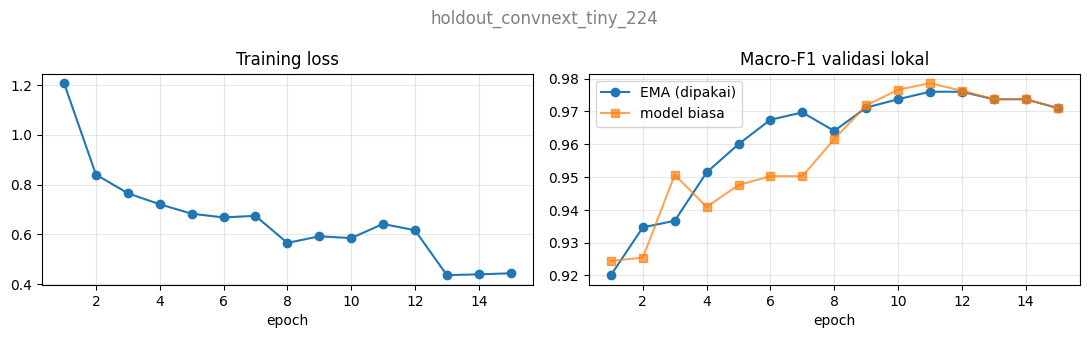

In [ ]:
# Grafik Training dan Validasi
plot_history(res_a['history'], RUN_A)

### **6.4 Hasil Metrik Evaluasi**

In [ ]:
# Metrik evaluasi klasifikasi
def classification_metrics(y, probs):
    pred = probs.argmax(1)

    print(f'Macro-F1 : {macro_f1(y, probs):.4f}')
    print(f'Akurasi  : {accuracy_score(y, pred):.4f}')
    print(classification_report(
        y, pred,
        target_names=CLASSES,
        digits=4,
        zero_division=0
    ))

# Confusion Matrix
def plot_confusion_matrix(y, probs, title=''):
    pred = probs.argmax(1)
    cm = confusion_matrix(
        y, pred, labels=list(range(NUM_CLASSES))
    )

    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASSES, rotation=40, ha='right', fontsize=8)
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_yticklabels(CLASSES, fontsize=8)

    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(
                j, i, cm[i, j],
                ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black',
                fontsize=8
            )

    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Label asli')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

### **6.5 Macro-F1, Akurasi, dan Classification Report**

In [ ]:
classification_metrics(
    res_a['val_labels'],
    res_a['val_probs']
)

Macro-F1 : 0.9710
Akurasi  : 0.9734
               precision    recall  f1-score   support

botol_plastik     0.9630    1.0000    0.9811        78
gelas_plastik     0.9740    0.9615    0.9677        78
kertas_kardus     0.9298    0.9636    0.9464        55
saset_kemasan     0.9901    0.9901    0.9901       101
    styrofoam     0.9897    0.9505    0.9697       101

     accuracy                         0.9734       413
    macro avg     0.9693    0.9732    0.9710       413
 weighted avg     0.9738    0.9734    0.9734       413



### **6.6 Confusion Matrix**

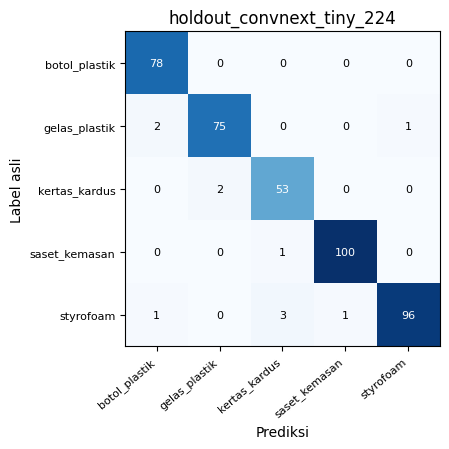

In [ ]:
plot_confusion_matrix(
    res_a['val_labels'],
    res_a['val_probs'],
    RUN_A
)

### **6.7 Analisis Kesalahan Prediksi**

=== Contoh Prediksi yang Salah ===
Menampilkan 4 dari 11 gambar yang salah diprediksi.


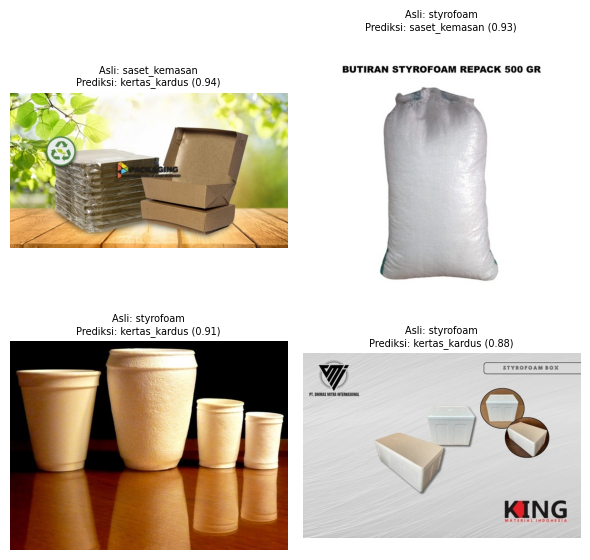

In [ ]:
show_errors(
    SPLIT['val'],
    res_a['val_labels'],
    res_a['val_probs'],
    k=4
)

## **7. Resolusi Uji + TTA, Export `submission/`, dan Self-Test**


### **7.1 Pindai resolusi uji dan TTA**

TTA adalah singkatan dari Test-Time Augmentation yang memiliki definisi sebagai teknik peningkatan performa model yang diterapkan pada fase inference, saat model diuji atau memprediksi data baru, bukan saat model sedang dilatih (training).

In [ ]:
def scan_eval_settings(tag, val_items, base_size):
    info = RUNS[tag]
    model = load_run_model(tag)
    sizes = sorted({base_size} | {int(round(base_size * f / 32) * 32) for f in (1.15, 1.3)})
    rows = []
    for s in sizes:
        dl = make_loader(val_items, build_eval_tf(s, info['mean'],
                                                  info['std']), 64, False, cfg)
        for tta in (False, True):
            p, y = run_eval(model, dl, tta=tta)
            rows.append(dict(size=s, tta=tta, val_F1=macro_f1(y, p),
                             val_acc=float(accuracy_score(y, p.argmax(1)))))
    del model
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    df = pd.DataFrame(rows)
    default = df[(df['size'] == base_size) & (df.tta)].iloc[0]
    best = df.sort_values(['val_F1', 'size'], ascending=[False, True]).iloc[0]
    chosen = best if best.val_F1 >= default.val_F1 + 0.003 else default
    return df, dict(size=int(chosen['size']), tta=bool(chosen.tta))


scan_df, EVAL_SETTINGS = scan_eval_settings(RUN_A, SPLIT['val'], cfg.img_size)
display(scan_df.round(4))
print('Pengaturan terpilih untuk submission:', EVAL_SETTINGS)

,size,tta,val_F1,val_acc
0,224,False,0.9710,0.9734
1,224,True,0.9761,0.9782
2,256,False,0.9739,0.9758
3,256,True,0.9743,0.9758
4,288,False,0.9806,0.9831
5,288,True,0.9759,0.9782


Pengaturan terpilih untuk submission: {'size': 288, 'tta': False}


### **7.2 Export: `submission/model.py`, `model.pth`, `requirements.txt`**


In [ ]:
MODEL_PY_TEMPLATE = '''# Submission Studio 2 - Klasifikasi Sampah (IF25-40401)
# File ini dihasilkan otomatis oleh notebook pelatihan. get_model() hanya membangun arsitektur;
# bobot dimuat oleh evaluate.py dari model.pth. Urutan kelas (alfabetis, = ImageFolder):
# 0 botol_plastik, 1 gelas_plastik, 2 kertas_kardus, 3 saset_kemasan, 4 styrofoam
import torch
import torch.nn as nn
import timm
from torchvision import transforms
from torchvision.transforms import InterpolationMode

NUM_CLASSES = 5
ARCHS = @ARCHS@
IMG_SIZE = @SIZE@
MEAN = @MEAN@
STD = @STD@
TTA_FLIP = @TTA@


class Ensemble(nn.Module):
    def __init__(self, archs, tta_flip):
        super().__init__()
        self.members = nn.ModuleList(
            [timm.create_model(a, pretrained=False, num_classes=NUM_CLASSES) for a in archs])
        self.tta_flip = tta_flip

    def forward(self, x):
        total, n = 0.0, 0
        for m in self.members:
            views = (x, torch.flip(x, dims=[-1])) if self.tta_flip else (x,)
            for v in views:
                total = total + m(v).float().softmax(dim=-1)
                n += 1
        return (total / n).clamp_min(1e-8).log()


def get_model():
    return Ensemble(ARCHS, TTA_FLIP)


def get_transform():
    return transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BICUBIC),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
'''


def load_submission_module(sub_dir='submission'):
    sub = Path(sub_dir).resolve()
    spec = importlib.util.spec_from_file_location('submission_model', sub / 'model.py')
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


def export_submission(tags, size, tta, half='auto', sub_dir='submission'):
    sub = Path(sub_dir)
    sub.mkdir(parents=True, exist_ok=True)
    infos = [RUNS[t] for t in tags]
    if len({tuple(i['mean']) for i in infos}) > 1 or len({tuple(i['std']) for i in infos}) > 1:
        raise ValueError('Anggota ensemble harus punya mean/std yang sama (satu get_transform untuk semuanya).')
    mean, std = infos[0]['mean'], infos[0]['std']
    code_txt = (MODEL_PY_TEMPLATE
                .replace('@ARCHS@', repr([i['arch'] for i in infos]))
                .replace('@SIZE@', str(int(size)))
                .replace('@MEAN@', repr(tuple(round(float(m), 6) for m in mean)))
                .replace('@STD@', repr(tuple(round(float(s), 6) for s in std)))
                .replace('@TTA@', repr(bool(tta))))
    (sub / 'model.py').write_text(code_txt, encoding='utf-8')

    merged = {}
    for i, info in enumerate(infos):
        st = torch.load(info['state_path'], map_location='cpu', weights_only=True)
        for k, v in st.items():
            merged[f'members.{i}.{k}'] = v
    mb32 = sum(v.numel() * v.element_size() for v in merged.values()) / 2 ** 20
    use_half = (half is True) or (half == 'auto' and mb32 > 90)
    if use_half:
        merged = {k: (v.half() if v.is_floating_point() else v) for k, v in merged.items()}
    torch.save(merged, sub / 'model.pth')
    (sub / 'requirements.txt').write_text(f'timm=={timm.__version__}\n')

    size_mb = os.path.getsize(sub / 'model.pth') / 2 ** 20
    print(f'model.py, model.pth, requirements.txt ditulis ke {sub}/')
    print(f'  anggota: {tags} | resolusi {size} | TTA flip {tta} | bobot {"fp16" if use_half else "fp32"} | model.pth {size_mb:.1f} MB')
    if size_mb > 500:
        print('  !! MELEBIHI batas 500 MB.')
    elif size_mb > 100:
        print('  ! > 100 MB: GitHub menolak push biasa. Pakai Git LFS atau GitHub Release dan tulis tautannya di README.')
    else:
        print('  OK: < 100 MB, bisa langsung di-commit.')

    # Arsitektur dari model.py memuat model.pth dengan strict=True
    mod = load_submission_module(sub_dir)
    m = mod.get_model()
    m.load_state_dict(torch.load(sub / 'model.pth', map_location='cpu',
                                 weights_only=True), strict=True)
    m.eval()
    with torch.no_grad():
        o = m(torch.randn(2, 3, int(size), int(size)))
    assert tuple(o.shape) == (2, NUM_CLASSES), o.shape
    print(f'  verifikasi: strict load OK, output {tuple(o.shape)}')
    backup_to_drive()
    return size_mb


export_submission([RUN_A], EVAL_SETTINGS['size'], EVAL_SETTINGS['tta'])

model.py, model.pth, requirements.txt ditulis ke submission/
  anggota: ['holdout_convnext_tiny_224'] | resolusi 288 | TTA flip False | bobot fp16 | model.pth 53.1 MB
  OK: < 100 MB, bisa langsung di-commit.
  verifikasi: strict load OK, output (2, 5)
[backup] 1 file disalin ke /content/drive/MyDrive/studio2_backup


53.11367321014404

### **7.3 Self-test dengan `evaluate.py`**


In [ ]:
EVAL_URL = 'https://raw.githubusercontent.com/informatika-itera/deep-learning-IF25-40401/main/materials/studio-2/starter-kit/evaluate.py'


def ensure_evaluate_py():
    if not Path('evaluate.py').exists():
        for cand in ('/content/drive/MyDrive/dataset_mahasiswa/starter_kit/evaluate.py',
                     '/content/drive/MyDrive/starter_kit/evaluate.py',
                     '/content/drive/MyDrive/dataset_studio2/evaluate.py',
                     '/content/evaluate.py'):
            if Path(cand).exists():
                shutil.copy2(cand, 'evaluate.py')
                print(f'evaluate.py disalin dari {cand}')
                return
        try:
            urllib.request.urlretrieve(EVAL_URL, 'evaluate.py')
            print('evaluate.py diunduh dari repo mata kuliah.')
        except Exception as e:
            raise SystemExit(f'Gagal mengunduh evaluate.py ({e}). Salin dari starter kit ke root repo.')


def run_official_eval(data='my_val', sub='submission'):
    ensure_evaluate_py()
    r = subprocess.run([sys.executable, 'evaluate.py', '--submission',
                        f'./{sub}', '--data', f'./{data}',
                        '--out', 'eval_result.json'],
                       capture_output=True, text=True)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr[-1500:])
        raise SystemExit('evaluate.py GAGAL: perbaiki sebelum commit.')
    return json.loads(Path('eval_result.json').read_text())


def cpu_budget_check(sub='submission', n_val=740, n=32, limit_min=15):
    mod = load_submission_module(sub)
    # Bobot acak untuk mengukur waktu
    model = mod.get_model().eval()
    tf = mod.get_transform()
    files = [p for c in CLASSES for p in sorted(Path('my_val', c).glob('*'))]
    files = random.Random(0).sample(files, min(n, len(files)))
    prev_threads = torch.get_num_threads()
    torch.set_num_threads(max(1, os.cpu_count() or 1))
    t0 = time.time()
    x = torch.stack([tf(Image.open(p).convert('RGB')) for p in files])
    t_pre = time.time() - t0
    with torch.no_grad():
        model(x[:4])
        t0 = time.time()
        model(x)
        t_fwd = time.time() - t0
    torch.set_num_threads(prev_threads)
    est_min = (t_pre + t_fwd) / len(files) * n_val / 60
    print(f'CPU ({os.cpu_count()} core): praproses {t_pre / len(files) * 1000:.0f} ms/gambar + forward {t_fwd / len(files) * 1000:.0f} ms/gambar'
          f' -> perkiraan {est_min:.1f} menit untuk {n_val} gambar (batas {limit_min} menit)')
    if est_min > limit_min / 2:
        print('PERINGATAN: perkiraan > separuh batas. Mesin asisten bisa lebih lambat: kecilkan resolusi/ensemble atau matikan TTA.')
    else:
        print('Anggaran waktu CPU aman.')


off = run_official_eval()
f1_nb = scan_df[(scan_df['size'] == EVAL_SETTINGS['size']) & (scan_df.tta == EVAL_SETTINGS['tta'])].val_F1.iloc[0]
print(f'Macro-F1 evaluate.py resmi: {off["macro_f1"]:.4f} | di notebook (cache + bobot fp32): {f1_nb:.4f} | selisih {off["macro_f1"] - f1_nb:+.4f}')
cpu_budget_check()

evaluate.py diunduh dari repo mata kuliah.
device=cuda  gambar=413

Macro-F1 : 0.9813
Akurasi  : 0.9831
  F1 botol_plastik   1.0000
  F1 gelas_plastik   0.9806
  F1 kertas_kardus   0.9558
  F1 saset_kemasan   0.9901
  F1 styrofoam       0.9800
Confusion matrix (baris = label asli, kolom = prediksi):
  botol_plastik   [78, 0, 0, 0, 0]
  gelas_plastik   [0, 76, 1, 0, 1]
  kertas_kardus   [0, 1, 54, 0, 0]
  saset_kemasan   [0, 0, 1, 100, 0]
  styrofoam       [0, 0, 2, 1, 98]

Macro-F1 evaluate.py resmi: 0.9813 | di notebook (cache + bobot fp32): 0.9806 | selisih +0.0007
CPU (2 core): praproses 15 ms/gambar + forward 217 ms/gambar -> perkiraan 2.9 menit untuk 740 gambar (batas 15 menit)
Anggaran waktu CPU aman.


## **8. Import Seluruh File dalam .zip**

In [ ]:
import zipfile

# Import file .zip
PACKAGE_FILES = ['submission/model.py', 'submission/model.pth',
                 'submission/requirements.txt', 'evaluate.py']


def package_zip(out='studio2_submission.zip'):
    with zipfile.ZipFile(out, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in PACKAGE_FILES:
            if Path(p).exists():
                z.write(p)
            else:
                print('(tidak ada)', p)
    print(f'{out}: {os.path.getsize(out) / 2 ** 20:.1f} MB')
    if IN_COLAB:
        from google.colab import files
        files.download(out)

# Eksekusi file .zip
RUN_PACKAGE = True
if RUN_PACKAGE:
    package_zip()

studio2_submission.zip: 49.2 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>